In [1]:
print("Welcome to E-Commerce Sales Analysis Project!")

Welcome to E-Commerce Sales Analysis Project!


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
df = pd.read_csv(
    "../data/raw/Sample - Superstore.csv",
    encoding="cp1252"
)

In [5]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [6]:
df.shape

(9994, 21)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 18  Quantity       9994

In [8]:
df.describe()

,Row ID,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,55190.379428,229.858001,3.789574,0.156203,28.656896
std,2885.163629,32063.693350,623.245101,2.225110,0.206452,234.260108
min,1.000000,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2499.250000,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,4997.500000,56430.500000,54.490000,3.000000,0.200000,8.666500
75%,7495.750000,90008.000000,209.940000,5.000000,0.200000,29.364000
max,9994.000000,99301.000000,22638.480000,14.000000,0.800000,8399.976000


In [9]:
df.columns

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State',
       'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category',
       'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit'],
      dtype='str')

In [10]:
df.isnull().sum()

Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
# Create a copy of original dataset

df_clean = df.copy()

print("Backup created successfully!")

Backup created successfully!


In [13]:
df_clean["Order Date"] = pd.to_datetime(
    df_clean["Order Date"],
    format="%m/%d/%Y"
)

df_clean["Ship Date"] = pd.to_datetime(
    df_clean["Ship Date"],
    format="%m/%d/%Y"
)

In [14]:
df_clean[["Order Date", "Ship Date"]].dtypes

Order Date    datetime64[us]
Ship Date     datetime64[us]
dtype: object

In [15]:
df_clean.duplicated().sum()

np.int64(0)

In [16]:
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row ID         9994 non-null   int64         
 1   Order ID       9994 non-null   str           
 2   Order Date     9994 non-null   datetime64[us]
 3   Ship Date      9994 non-null   datetime64[us]
 4   Ship Mode      9994 non-null   str           
 5   Customer ID    9994 non-null   str           
 6   Customer Name  9994 non-null   str           
 7   Segment        9994 non-null   str           
 8   Country        9994 non-null   str           
 9   City           9994 non-null   str           
 10  State          9994 non-null   str           
 11  Postal Code    9994 non-null   int64         
 12  Region         9994 non-null   str           
 13  Product ID     9994 non-null   str           
 14  Category       9994 non-null   str           
 15  Sub-Category   9994 non-null   s

In [17]:
(df_clean["Quantity"] <= 0).sum()

np.int64(0)

In [18]:
(df_clean["Sales"] < 0).sum()

np.int64(0)

In [19]:
df_clean["Discount"].describe()

count    9994.000000
mean        0.156203
std         0.206452
min         0.000000
25%         0.000000
50%         0.200000
75%         0.200000
max         0.800000
Name: Discount, dtype: float64

In [20]:
df_clean["Shipping Days"] = (
    df_clean["Ship Date"] - df_clean["Order Date"]
).dt.days

In [21]:
df_clean[["Order Date", "Ship Date", "Shipping Days"]].head()

,Order Date,Ship Date,Shipping Days
0,2016-11-08,2016-11-11,3
1,2016-11-08,2016-11-11,3
2,2016-06-12,2016-06-16,4
3,2015-10-11,2015-10-18,7
4,2015-10-11,2015-10-18,7


In [22]:
# Overall Business Performance

total_sales = df_clean["Sales"].sum()

total_profit = df_clean["Profit"].sum()

total_quantity = df_clean["Quantity"].sum()

total_orders = df_clean["Order ID"].nunique()

print("Total Sales:", round(total_sales, 2))
print("Total Profit:", round(total_profit, 2))
print("Total Quantity Sold:", total_quantity)
print("Total Unique Orders:", total_orders)

Total Sales: 2297200.86
Total Profit: 286397.02
Total Quantity Sold: 37873
Total Unique Orders: 5009


In [23]:
average_order_value = total_sales / total_orders

print("Average Order Value:", round(average_order_value, 2))

Average Order Value: 458.61


In [24]:
profit_margin = (total_profit / total_sales) * 100

print("Profit Margin:", round(profit_margin, 2), "%")

Profit Margin: 12.47 %


In [25]:
category_analysis = df_clean.groupby("Category").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum")
)

category_analysis

,Total_Sales,Total_Profit,Total_Quantity
Category,,,
Furniture,741999.7953,18451.2728,8028
Office Supplies,719047.0320,122490.8008,22906
Technology,836154.0330,145454.9481,6939


In [26]:
category_analysis.sort_values(
    by="Total_Sales",
    ascending=False
)

,Total_Sales,Total_Profit,Total_Quantity
Category,,,
Technology,836154.0330,145454.9481,6939
Furniture,741999.7953,18451.2728,8028
Office Supplies,719047.0320,122490.8008,22906


In [27]:
category_analysis.sort_values(
    by="Total_Profit",
    ascending=False
)

,Total_Sales,Total_Profit,Total_Quantity
Category,,,
Technology,836154.0330,145454.9481,6939
Office Supplies,719047.0320,122490.8008,22906
Furniture,741999.7953,18451.2728,8028


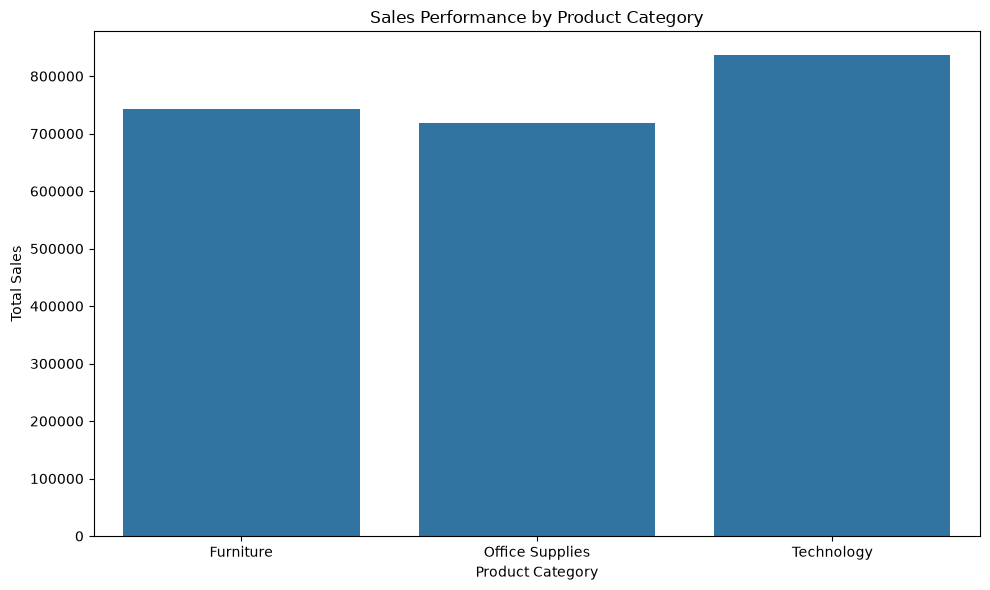

In [28]:
# Category-wise Sales Visualization

plt.figure(figsize=(10, 6))

sns.barplot(
    data=category_analysis.reset_index(),
    x="Category",
    y="Total_Sales"
)

plt.title("Sales Performance by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Sales")

plt.tight_layout()

plt.savefig("../outputs/charts/category_sales.png")

plt.show()

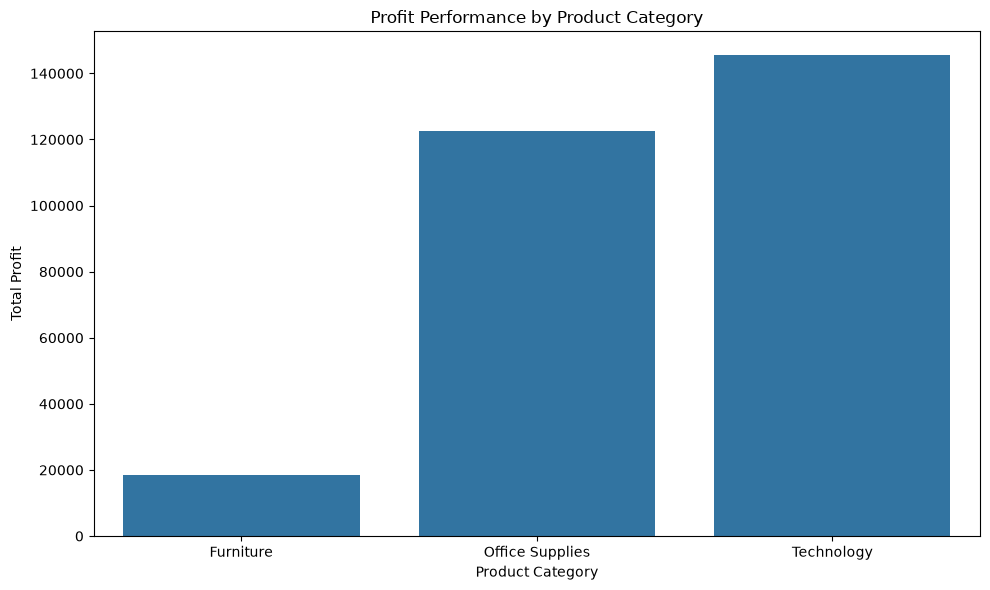

In [29]:
# Category-wise Profit Visualization

plt.figure(figsize=(10, 6))

sns.barplot(
    data=category_analysis.reset_index(),
    x="Category",
    y="Total_Profit"
)

plt.title("Profit Performance by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Profit")

plt.tight_layout()

plt.savefig("../outputs/charts/category_profit.png")

plt.show()

In [30]:
# Region-wise Business Analysis

region_analysis = df_clean.groupby("Region").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum"),
    Total_Orders=("Order ID", "nunique")
)

region_analysis

,Total_Sales,Total_Profit,Total_Quantity,Total_Orders
Region,,,,
Central,501239.8908,39706.3625,8780,1175
East,678781.2400,91522.7800,10618,1401
South,391721.9050,46749.4303,6209,822
West,725457.8245,108418.4489,12266,1611


In [31]:
region_analysis.sort_values(
    by="Total_Sales",
    ascending=False
)

,Total_Sales,Total_Profit,Total_Quantity,Total_Orders
Region,,,,
West,725457.8245,108418.4489,12266,1611
East,678781.2400,91522.7800,10618,1401
Central,501239.8908,39706.3625,8780,1175
South,391721.9050,46749.4303,6209,822


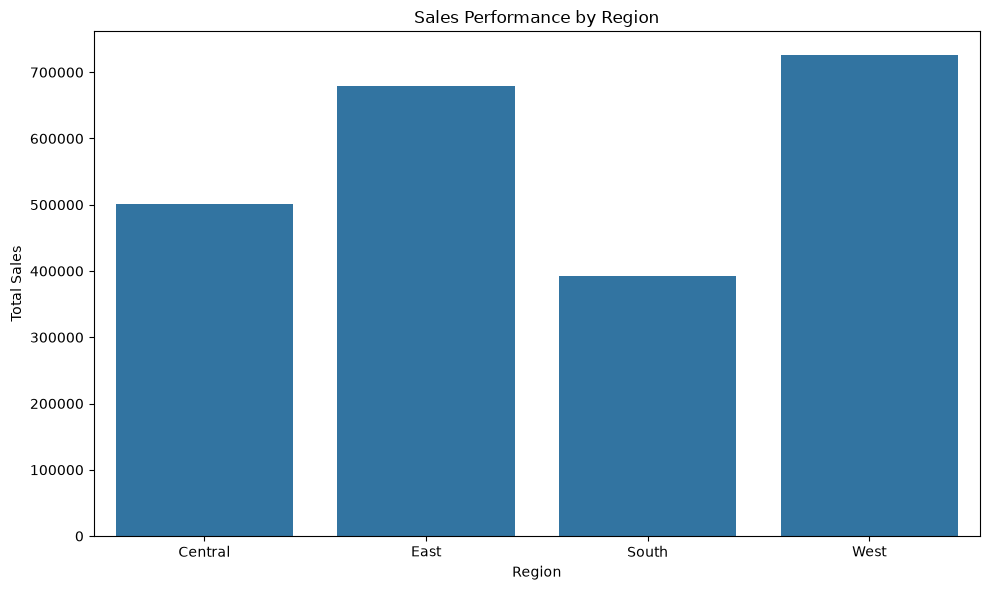

In [32]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=region_analysis.reset_index(),
    x="Region",
    y="Total_Sales"
)

plt.title("Sales Performance by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales")

plt.tight_layout()

plt.savefig("../outputs/charts/region_sales.png")

plt.show()

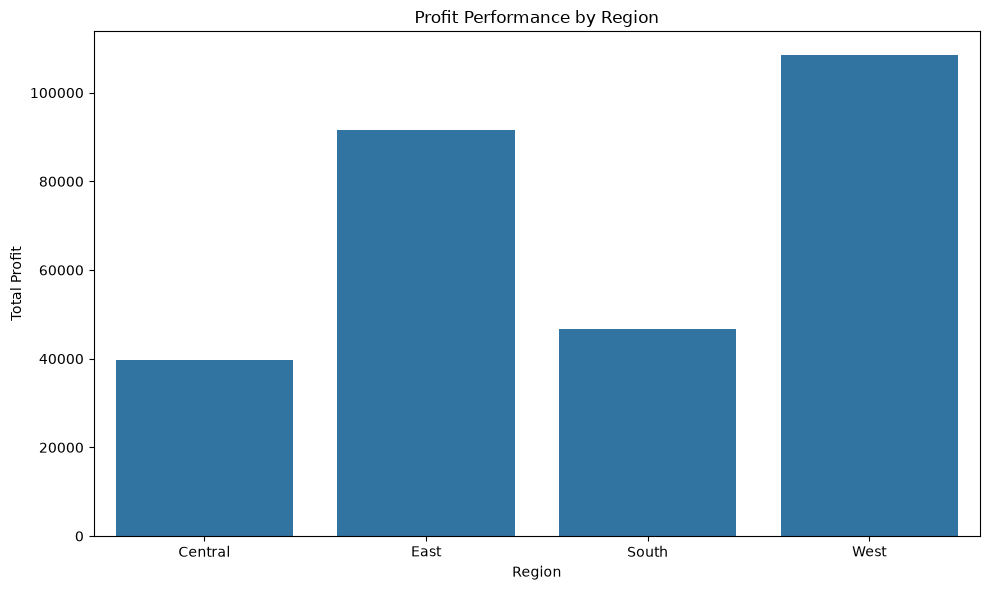

In [33]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=region_analysis.reset_index(),
    x="Region",
    y="Total_Profit"
)

plt.title("Profit Performance by Region")
plt.xlabel("Region")
plt.ylabel("Total Profit")

plt.tight_layout()

plt.savefig("../outputs/charts/region_profit.png")

plt.show()

In [34]:
# Extract Year and Month from Order Date

df_clean["Year-Month"] = df_clean["Order Date"].dt.to_period("M")

df_clean[["Order Date", "Year-Month"]].head()

,Order Date,Year-Month
0,2016-11-08,2016-11
1,2016-11-08,2016-11
2,2016-06-12,2016-06
3,2015-10-11,2015-10
4,2015-10-11,2015-10


In [35]:
monthly_sales = df_clean.groupby("Year-Month").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order ID", "nunique")
)

monthly_sales.head()

,Total_Sales,Total_Profit,Total_Orders
Year-Month,,,
2014-01,14236.895,2450.1907,32
2014-02,4519.892,862.3084,28
2014-03,55691.009,498.7299,71
2014-04,28295.345,3488.8352,66
2014-05,23648.287,2738.7096,69


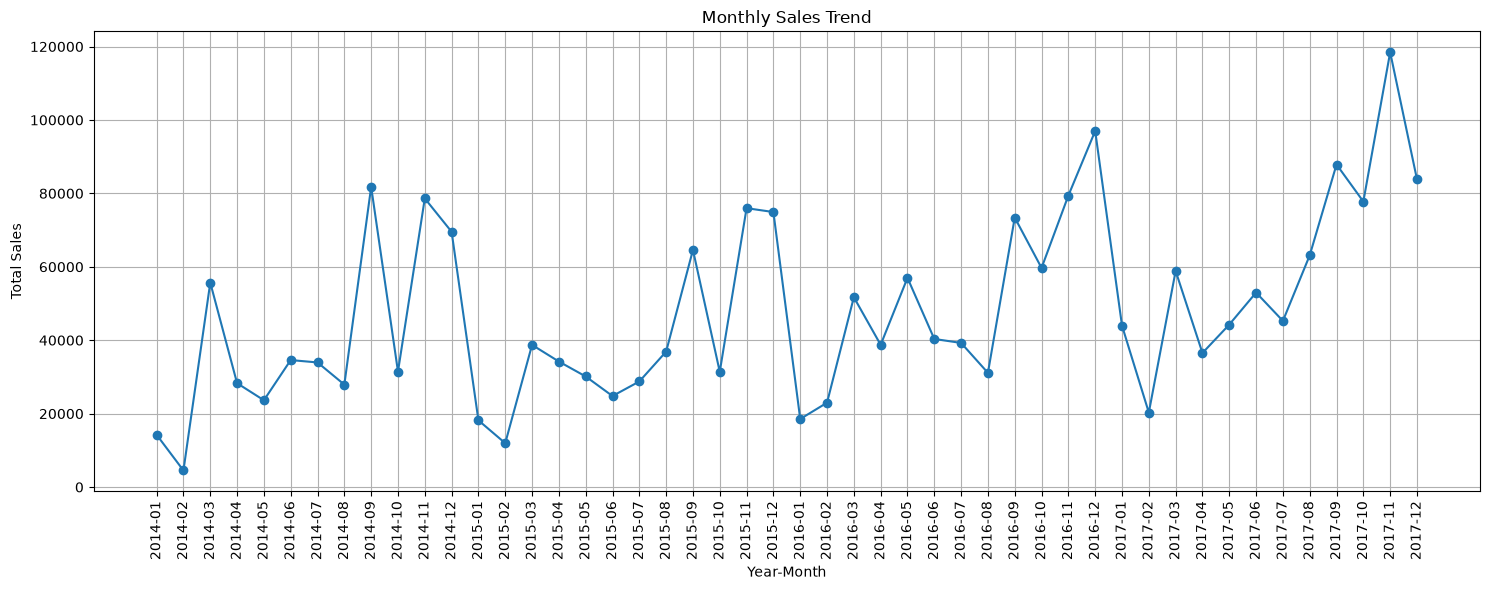

In [36]:
plt.figure(figsize=(15, 6))

plt.plot(
    monthly_sales.index.astype(str),
    monthly_sales["Total_Sales"],
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Year-Month")
plt.ylabel("Total Sales")

plt.xticks(rotation=90)
plt.grid(True)
plt.tight_layout()

plt.savefig("../outputs/charts/monthly_sales_trend.png")

plt.show()

In [37]:
monthly_sales.sort_values(
    by="Total_Sales",
    ascending=False
).head(5)

,Total_Sales,Total_Profit,Total_Orders
Year-Month,,,
2017-11,118447.8250,9690.1037,261
2016-12,96999.0430,17885.3093,176
2017-09,87866.6520,10991.5556,226
2017-12,83829.3188,8483.3468,224
2014-09,81777.3508,8328.0994,130


In [38]:
monthly_sales.sort_values(
    by="Total_Sales",
    ascending=True
).head(5)

,Total_Sales,Total_Profit,Total_Orders
Year-Month,,,
2014-02,4519.8920,862.3084,28
2015-02,11951.4110,2813.8508,36
2014-01,14236.8950,2450.1907,32
2015-01,18174.0756,-3281.0070,29
2016-01,18542.4910,2824.8233,48


In [39]:
# Product-wise Business Analysis

product_analysis = df_clean.groupby("Product Name").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum")
)

product_analysis.head()

,Total_Sales,Total_Profit,Total_Quantity
Product Name,,,
"""While you Were Out"" Message Book, One Form per Page",25.228,10.3880,8
"#10 Gummed Flap White Envelopes, 100/Box",41.300,16.7678,11
#10 Self-Seal White Envelopes,108.682,52.1230,10
"#10 White Business Envelopes,4 1/8 x 9 1/2",488.904,223.1408,32
"#10- 4 1/8"" x 9 1/2"" Recycled Envelopes",286.672,115.2806,37


In [40]:
top_10_sales = product_analysis.sort_values(
    by="Total_Sales",
    ascending=False
).head(10)

top_10_sales

,Total_Sales,Total_Profit,Total_Quantity
Product Name,,,
Canon imageCLASS 2200 Advanced Copier,61599.824,2.519993e+04,20
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind,27453.384,7.753039e+03,31
Cisco TelePresence System EX90 Videoconferencing Unit,22638.480,-1.811078e+03,6
HON 5400 Series Task Chairs for Big and Tall,21870.576,5.684342e-14,39
GBC DocuBind TL300 Electric Binding System,19823.479,2.233505e+03,37
GBC Ibimaster 500 Manual ProClick Binding System,19024.500,7.609800e+02,48
Hewlett Packard LaserJet 3310 Copier,18839.686,6.983884e+03,38
"HP Designjet T520 Inkjet Large Format Printer - 24"" Color",18374.895,4.094977e+03,12
GBC DocuBind P400 Electric Binding System,17965.068,-1.878166e+03,27


In [41]:
top_10_profit = product_analysis.sort_values(
    by="Total_Profit",
    ascending=False
).head(10)

top_10_profit

,Total_Sales,Total_Profit,Total_Quantity
Product Name,,,
Canon imageCLASS 2200 Advanced Copier,61599.824,25199.9280,20
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind,27453.384,7753.0390,31
Hewlett Packard LaserJet 3310 Copier,18839.686,6983.8836,38
Canon PC1060 Personal Laser Copier,11619.834,4570.9347,19
"HP Designjet T520 Inkjet Large Format Printer - 24"" Color",18374.895,4094.9766,12
Ativa V4110MDD Micro-Cut Shredder,7699.890,3772.9461,11
"3D Systems Cube Printer, 2nd Generation, Magenta",14299.890,3717.9714,11
Plantronics Savi W720 Multi-Device Wireless Headset System,9367.290,3696.2820,24
Ibico EPK-21 Electric Binding System,15875.916,3345.2823,13


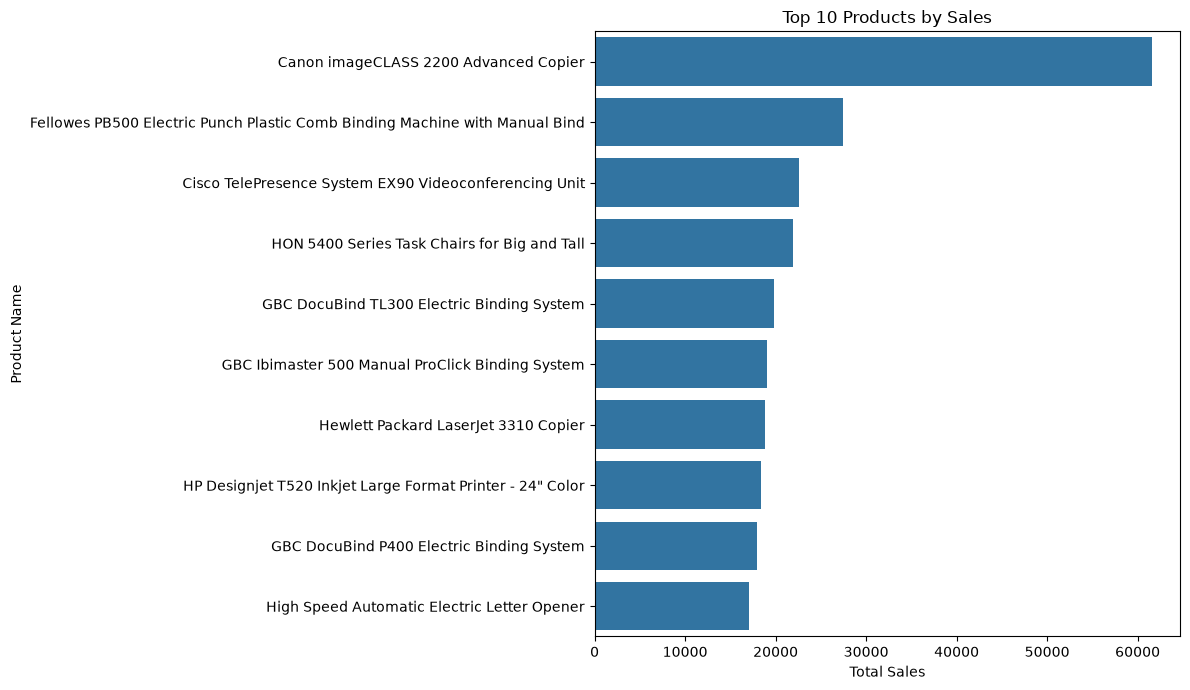

In [42]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_10_sales.reset_index(),
    x="Total_Sales",
    y="Product Name"
)

plt.title("Top 10 Products by Sales")
plt.xlabel("Total Sales")
plt.ylabel("Product Name")

plt.tight_layout()

plt.savefig("../outputs/charts/top_10_products_sales.png")

plt.show()

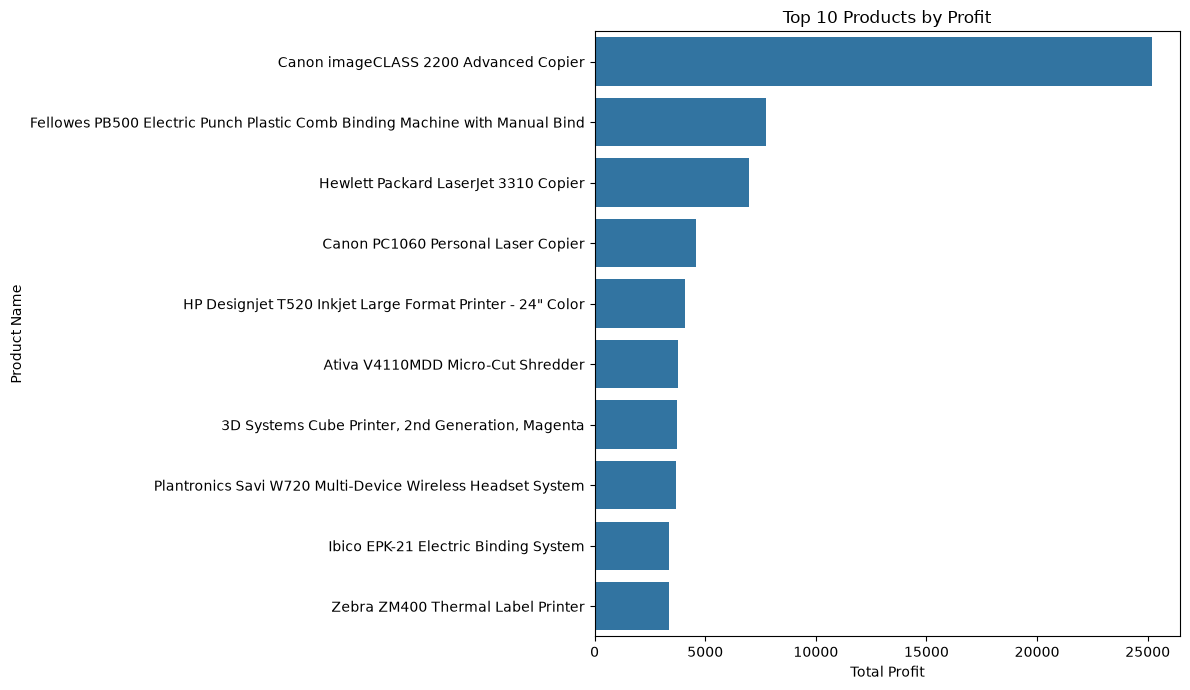

In [43]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_10_profit.reset_index(),
    x="Total_Profit",
    y="Product Name"
)

plt.title("Top 10 Products by Profit")
plt.xlabel("Total Profit")
plt.ylabel("Product Name")

plt.tight_layout()

plt.savefig("../outputs/charts/top_10_products_profit.png")

plt.show()

In [44]:
customer_analysis = df_clean.groupby(
    ["Customer ID", "Customer Name"]
).agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order ID", "nunique"),
    Total_Quantity=("Quantity", "sum")
)

customer_analysis.head()

,,Total_Sales,Total_Profit,Total_Orders,Total_Quantity
Customer ID,Customer Name,,,,
AA-10315,Alex Avila,5563.560,-362.8825,5,30
AA-10375,Allen Armold,1056.390,277.3824,9,41
AA-10480,Andrew Allen,1790.512,435.8274,4,36
AA-10645,Anna Andreadi,5086.935,857.8033,6,64
AB-10015,Aaron Bergman,886.156,129.3465,3,13


In [45]:
top_10_customers_sales = customer_analysis.sort_values(
    by="Total_Sales",
    ascending=False
).head(10)

top_10_customers_sales

,,Total_Sales,Total_Profit,Total_Orders,Total_Quantity
Customer ID,Customer Name,,,,
SM-20320,Sean Miller,25043.050,-1980.7393,5,50
TC-20980,Tamara Chand,19052.218,8981.3239,5,42
RB-19360,Raymond Buch,15117.339,6976.0959,6,71
TA-21385,Tom Ashbrook,14595.620,4703.7883,4,36
AB-10105,Adrian Barton,14473.571,5444.8055,10,73
KL-16645,Ken Lonsdale,14175.229,806.8550,12,113
SC-20095,Sanjit Chand,14142.334,5757.4119,9,87
HL-15040,Hunter Lopez,12873.298,5622.4292,6,50
SE-20110,Sanjit Engle,12209.438,2650.6769,11,78


In [46]:
top_10_customers_profit = customer_analysis.sort_values(
    by="Total_Profit",
    ascending=False
).head(10)

top_10_customers_profit

,,Total_Sales,Total_Profit,Total_Orders,Total_Quantity
Customer ID,Customer Name,,,,
TC-20980,Tamara Chand,19052.218,8981.3239,5,42
RB-19360,Raymond Buch,15117.339,6976.0959,6,71
SC-20095,Sanjit Chand,14142.334,5757.4119,9,87
HL-15040,Hunter Lopez,12873.298,5622.4292,6,50
AB-10105,Adrian Barton,14473.571,5444.8055,10,73
TA-21385,Tom Ashbrook,14595.620,4703.7883,4,36
CM-12385,Christopher Martinez,8954.020,3899.8904,4,34
KD-16495,Keith Dawkins,8181.256,3038.6254,12,84
AR-10540,Andy Reiter,6608.448,2884.6208,6,33


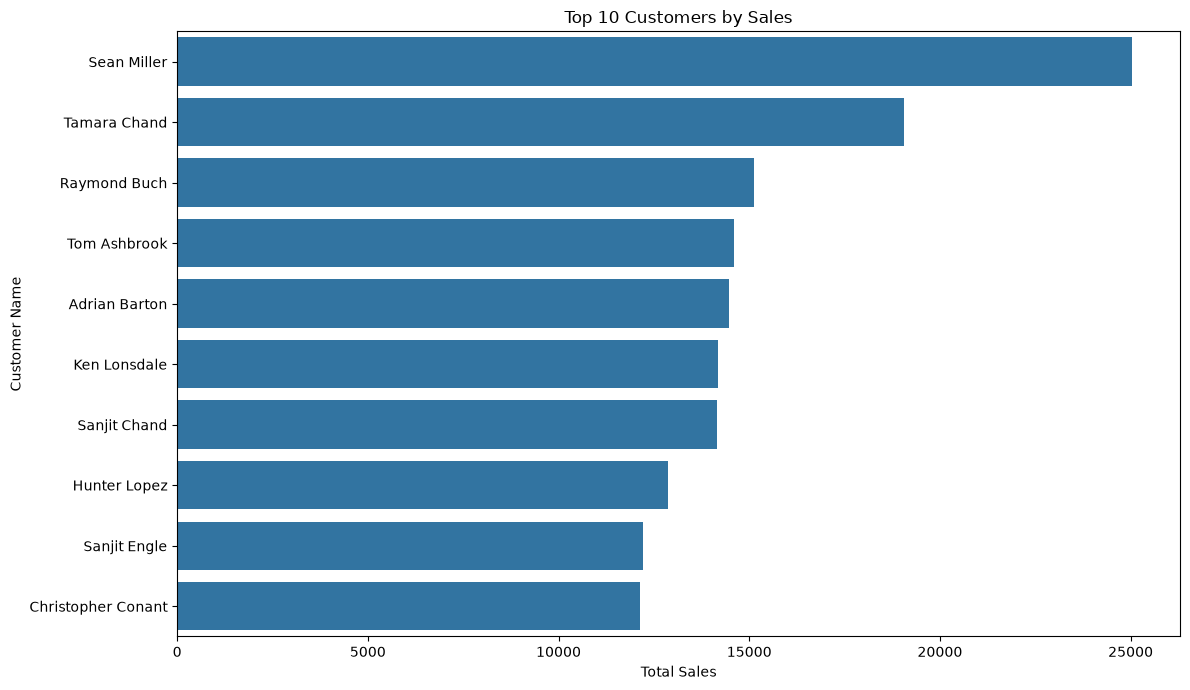

In [47]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_10_customers_sales.reset_index(),
    x="Total_Sales",
    y="Customer Name"
)

plt.title("Top 10 Customers by Sales")
plt.xlabel("Total Sales")
plt.ylabel("Customer Name")

plt.tight_layout()
plt.savefig("../outputs/charts/top_10_customers_sales.png")
plt.show()

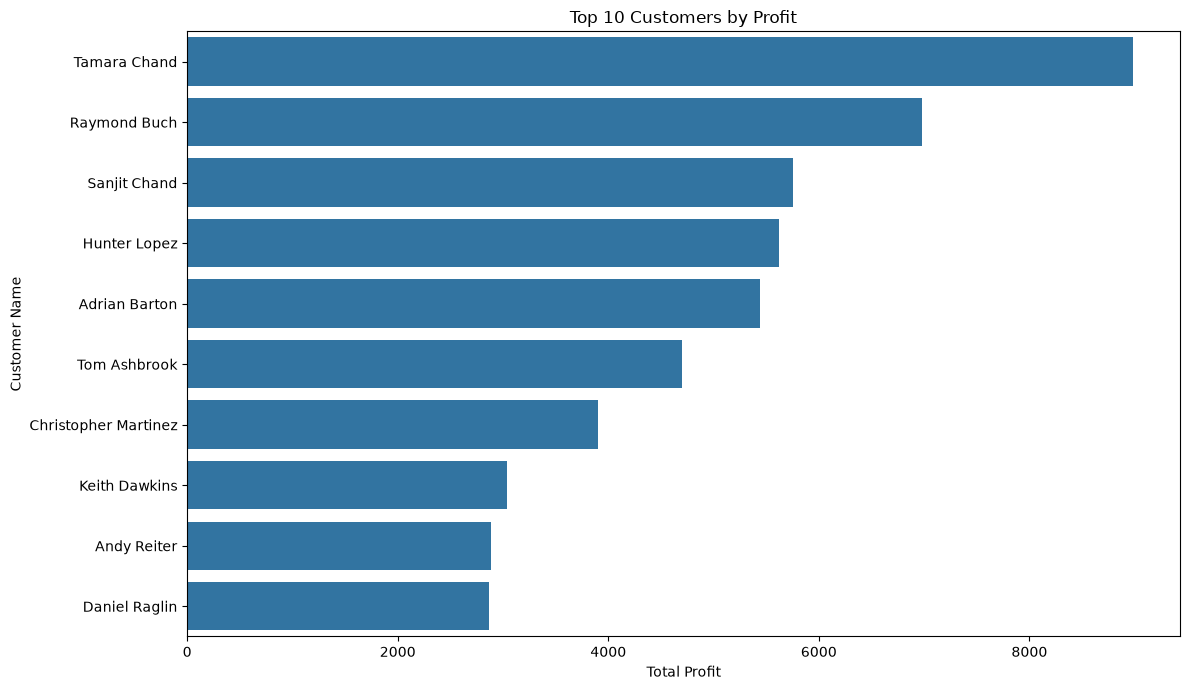

In [48]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_10_customers_profit.reset_index(),
    x="Total_Profit",
    y="Customer Name"
)

plt.title("Top 10 Customers by Profit")
plt.xlabel("Total Profit")
plt.ylabel("Customer Name")

plt.tight_layout()
plt.savefig("../outputs/charts/top_10_customers_profit.png")
plt.show()

In [49]:
segment_analysis = df_clean.groupby("Segment").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order ID", "nunique")
)

segment_analysis

,Total_Sales,Total_Profit,Total_Orders
Segment,,,
Consumer,1.161401e+06,134119.2092,2586
Corporate,7.061464e+05,91979.1340,1514
Home Office,4.296531e+05,60298.6785,909


In [50]:
loss_making_products = product_analysis[
    product_analysis["Total_Profit"] < 0
].sort_values(
    by="Total_Profit",
    ascending=True
)

loss_making_products.head(10)

,Total_Sales,Total_Profit,Total_Quantity
Product Name,,,
Cubify CubeX 3D Printer Double Head Print,11099.963,-8879.9704,9
Lexmark MX611dhe Monochrome Laser Printer,16829.901,-4589.9730,18
Cubify CubeX 3D Printer Triple Head Print,7999.980,-3839.9904,4
Chromcraft Bull-Nose Wood Oval Conference Tables & Bases,9917.640,-2876.1156,27
Bush Advantage Collection Racetrack Conference Table,9544.725,-1934.3976,33
GBC DocuBind P400 Electric Binding System,17965.068,-1878.1662,27
Cisco TelePresence System EX90 Videoconferencing Unit,22638.480,-1811.0784,6
Martin Yale Chadless Opener Electric Letter Opener,16656.200,-1299.1836,22
Balt Solid Wood Round Tables,6518.754,-1201.0581,19


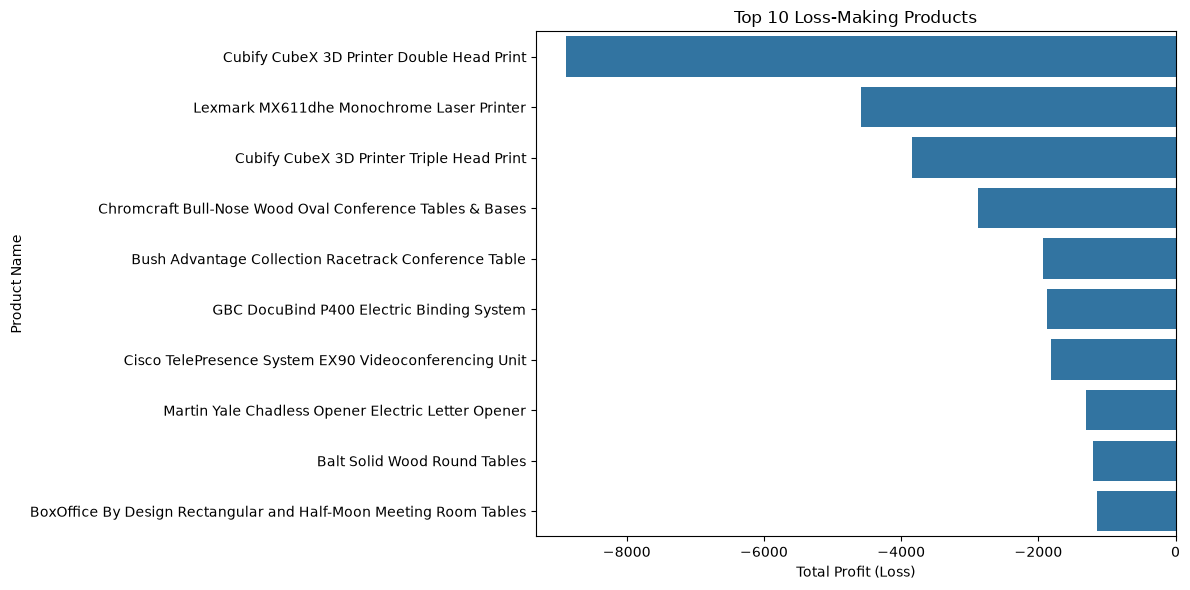

In [51]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=loss_making_products.head(10).reset_index(),
    x="Total_Profit",
    y="Product Name"
)

plt.title("Top 10 Loss-Making Products")
plt.xlabel("Total Profit (Loss)")
plt.ylabel("Product Name")
plt.tight_layout()

plt.savefig("../outputs/charts/loss_making_products.png")
plt.show()

In [52]:
subcategory_analysis = df_clean.groupby("Sub-Category").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum"),
    Average_Discount=("Discount", "mean")
)

subcategory_analysis["Profit_Margin"] = (
    subcategory_analysis["Total_Profit"]
    / subcategory_analysis["Total_Sales"]
) * 100

subcategory_analysis.sort_values(
    by="Total_Profit",
    ascending=True
)

,Total_Sales,Total_Profit,Total_Quantity,Average_Discount,Profit_Margin
Sub-Category,,,,,
Tables,206965.5320,-17725.4811,1241,0.261285,-8.564460
Bookcases,114879.9963,-3472.5560,868,0.211140,-3.022768
Supplies,46673.5380,-1189.0995,647,0.076842,-2.547695
Fasteners,3024.2800,949.5182,914,0.082028,31.396504
Machines,189238.6310,3384.7569,440,0.306087,1.788618
Labels,12486.3120,5546.2540,1400,0.068681,44.418672
Art,27118.7920,6527.7870,3000,0.074874,24.071083
Envelopes,16476.4020,6964.1767,906,0.080315,42.267582
Furnishings,91705.1640,13059.1436,3563,0.138349,14.240358


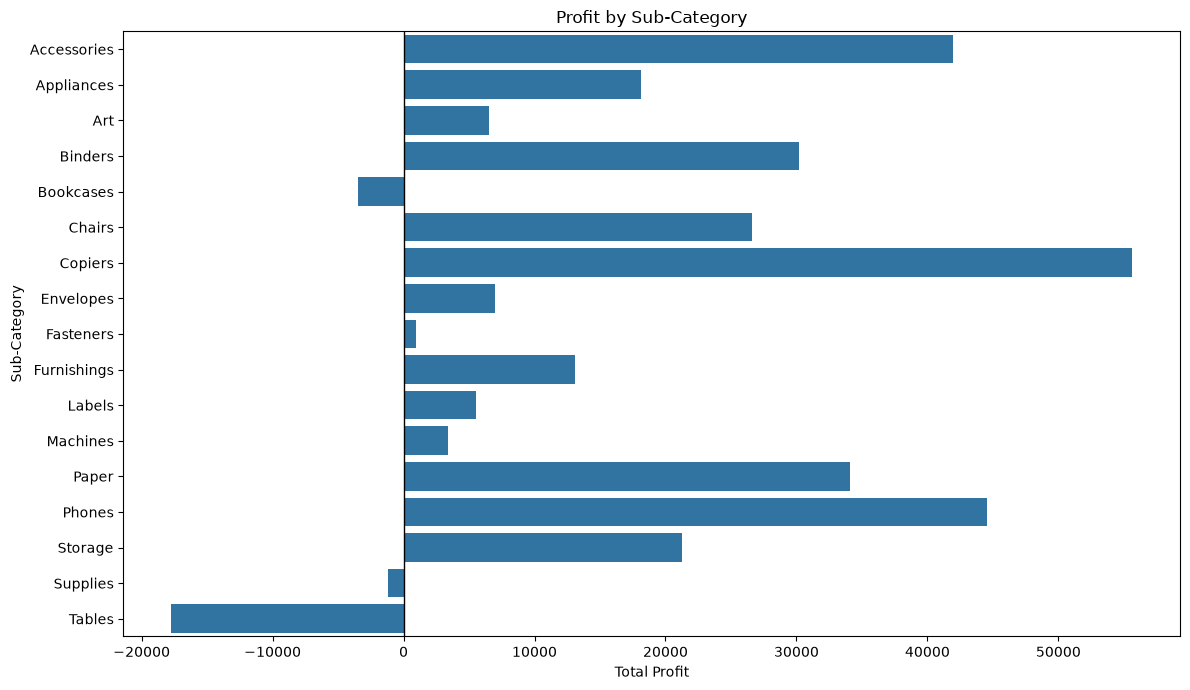

In [53]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=subcategory_analysis.reset_index(),
    x="Total_Profit",
    y="Sub-Category"
)

plt.axvline(x=0, color="black", linewidth=1)

plt.title("Profit by Sub-Category")
plt.xlabel("Total Profit")
plt.ylabel("Sub-Category")

plt.tight_layout()

plt.savefig("../outputs/charts/subcategory_profit.png")
plt.show()

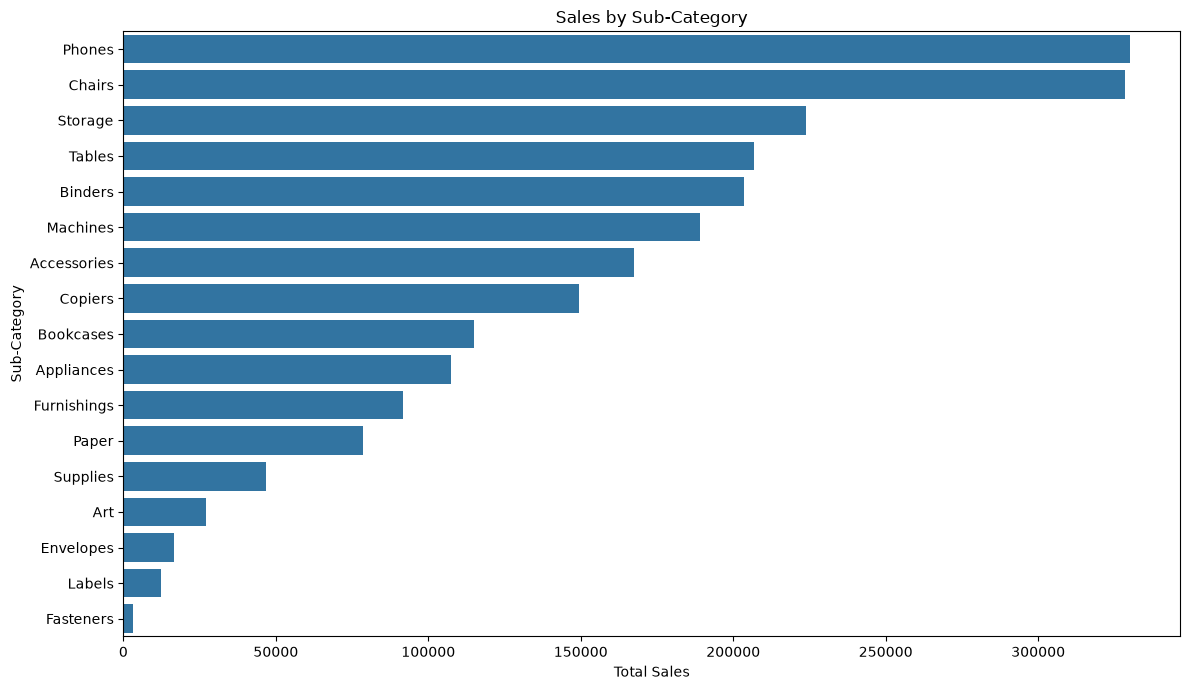

In [54]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=subcategory_analysis.reset_index().sort_values(
        by="Total_Sales", ascending=False
    ),
    x="Total_Sales",
    y="Sub-Category"
)

plt.title("Sales by Sub-Category")
plt.xlabel("Total Sales")
plt.ylabel("Sub-Category")

plt.tight_layout()

plt.savefig("../outputs/charts/subcategory_sales.png")
plt.show()

In [55]:
discount_analysis = df_clean.groupby("Discount").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Average_Profit=("Profit", "mean"),
    Total_Quantity=("Quantity", "sum"),
    Total_Orders=("Order ID", "nunique")
)

discount_analysis

,Total_Sales,Total_Profit,Average_Profit,Total_Quantity,Total_Orders
Discount,,,,,
0.00,1.087908e+06,320987.6032,66.900292,18267,2644
0.10,5.436935e+04,9029.1770,96.055074,373,89
0.15,2.755852e+04,1418.9915,27.288298,198,51
0.20,7.645944e+05,90337.3060,24.702572,13660,2407
0.30,1.032267e+05,-10369.2774,-45.679636,849,211
0.32,1.449346e+04,-2391.1377,-88.560656,105,27
0.40,1.164178e+05,-23057.0504,-111.927429,786,185
0.45,5.484974e+03,-2493.1111,-226.646464,45,10
0.50,5.891854e+04,-20506.4281,-310.703456,241,64


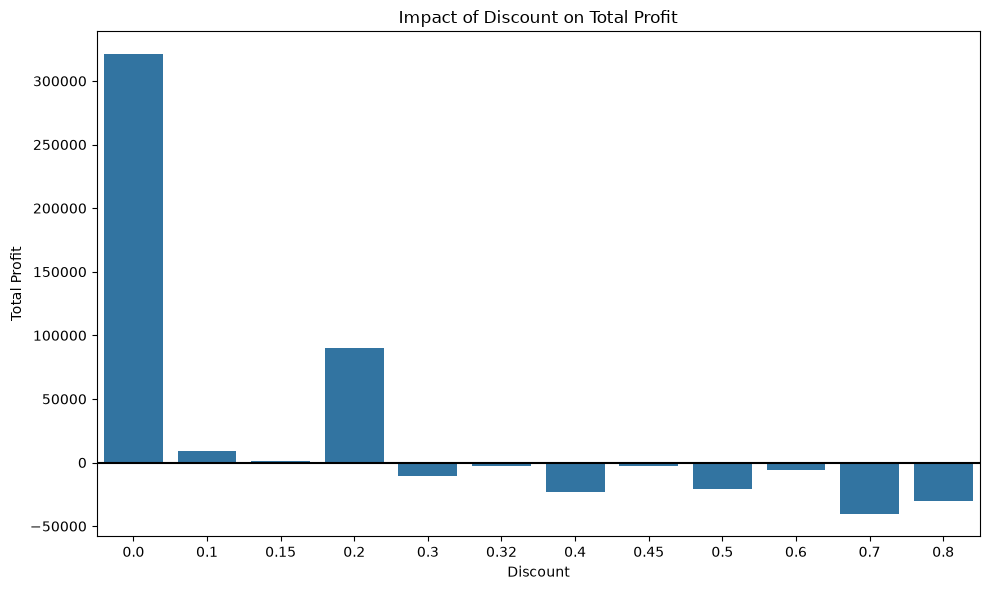

In [56]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=discount_analysis.reset_index(),
    x="Discount",
    y="Total_Profit"
)

plt.axhline(y=0, color="black")

plt.title("Impact of Discount on Total Profit")
plt.xlabel("Discount")
plt.ylabel("Total Profit")

plt.tight_layout()

plt.savefig("../outputs/charts/discount_vs_profit.png")
plt.show()

In [57]:
shipping_analysis = df_clean.groupby("Ship Mode").agg(
    Total_Orders=("Order ID", "nunique"),
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Average_Shipping_Days=("Shipping Days", "mean")
)

shipping_analysis

,Total_Orders,Total_Sales,Total_Profit,Average_Shipping_Days
Ship Mode,,,,
First Class,787,3.514284e+05,48969.8399,2.182705
Same Day,264,1.283631e+05,15891.7589,0.044199
Second Class,964,4.591936e+05,57446.6354,3.238046
Standard Class,2994,1.358216e+06,164088.7875,5.006535


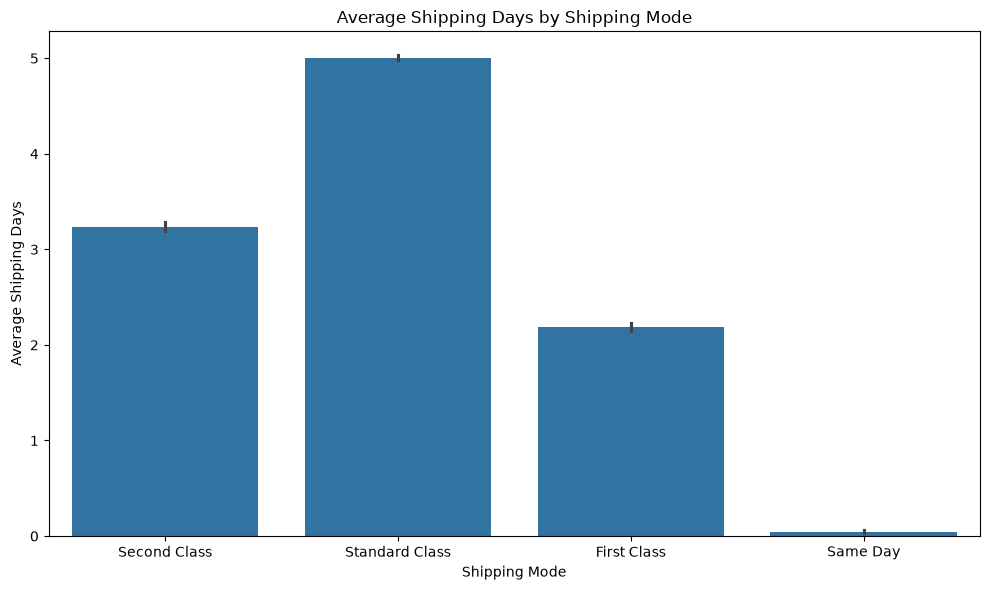

In [58]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=df_clean,
    x="Ship Mode",
    y="Shipping Days",
    estimator="mean"
)

plt.title("Average Shipping Days by Shipping Mode")
plt.xlabel("Shipping Mode")
plt.ylabel("Average Shipping Days")

plt.tight_layout()

plt.savefig("../outputs/charts/shipping_performance.png")
plt.show()

In [59]:
state_analysis = df_clean.groupby("State").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order ID", "nunique"),
    Total_Quantity=("Quantity", "sum")
)

state_analysis["Profit_Margin"] = (
    state_analysis["Total_Profit"]
    / state_analysis["Total_Sales"]
) * 100

In [60]:
top_10_states = state_analysis.sort_values(
    by="Total_Sales",
    ascending=False
).head(10)

top_10_states

,Total_Sales,Total_Profit,Total_Orders,Total_Quantity,Profit_Margin
State,,,,,
California,457687.6315,76381.3871,1021,7667,16.688541
New York,310876.2710,74038.5486,562,4224,23.816082
Texas,170188.0458,-25729.3563,487,3724,-15.118192
Washington,138641.2700,33402.6517,256,1883,24.092863
Pennsylvania,116511.9140,-15559.9603,288,2153,-13.354823
Florida,89473.7080,-3399.3017,200,1379,-3.799219
Illinois,80166.1010,-12607.8870,276,1845,-15.727205
Ohio,78258.1360,-16971.3766,236,1759,-21.686405
Michigan,76269.6140,24463.1876,117,946,32.074618


In [61]:
bottom_10_states = state_analysis.sort_values(
    by="Total_Profit",
    ascending=True
).head(10)

bottom_10_states

,Total_Sales,Total_Profit,Total_Orders,Total_Quantity,Profit_Margin
State,,,,,
Texas,170188.0458,-25729.3563,487,3724,-15.118192
Ohio,78258.1360,-16971.3766,236,1759,-21.686405
Pennsylvania,116511.9140,-15559.9603,288,2153,-13.354823
Illinois,80166.1010,-12607.8870,276,1845,-15.727205
North Carolina,55603.1640,-7490.9122,136,983,-13.472097
Colorado,32108.1180,-6527.8579,79,693,-20.330864
Tennessee,30661.8730,-5341.6936,91,681,-17.421289
Arizona,35282.0010,-3427.9246,108,862,-9.715789
Florida,89473.7080,-3399.3017,200,1379,-3.799219


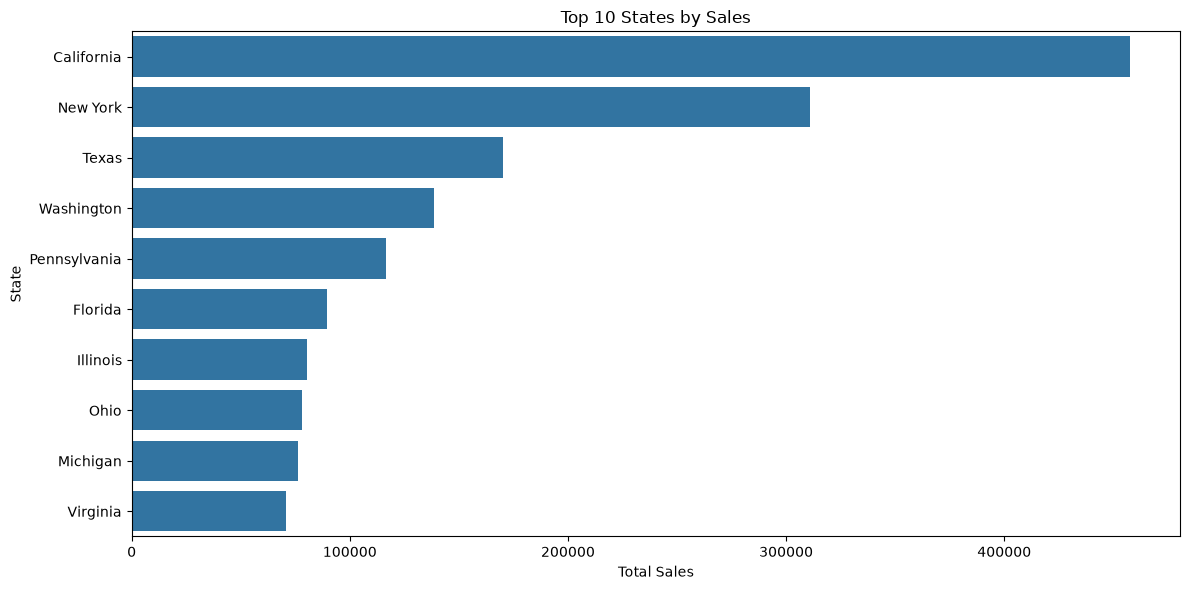

In [62]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_10_states.reset_index(),
    x="Total_Sales",
    y="State"
)

plt.title("Top 10 States by Sales")
plt.xlabel("Total Sales")
plt.ylabel("State")

plt.tight_layout()
plt.savefig("../outputs/charts/top_10_states_sales.png")
plt.show()

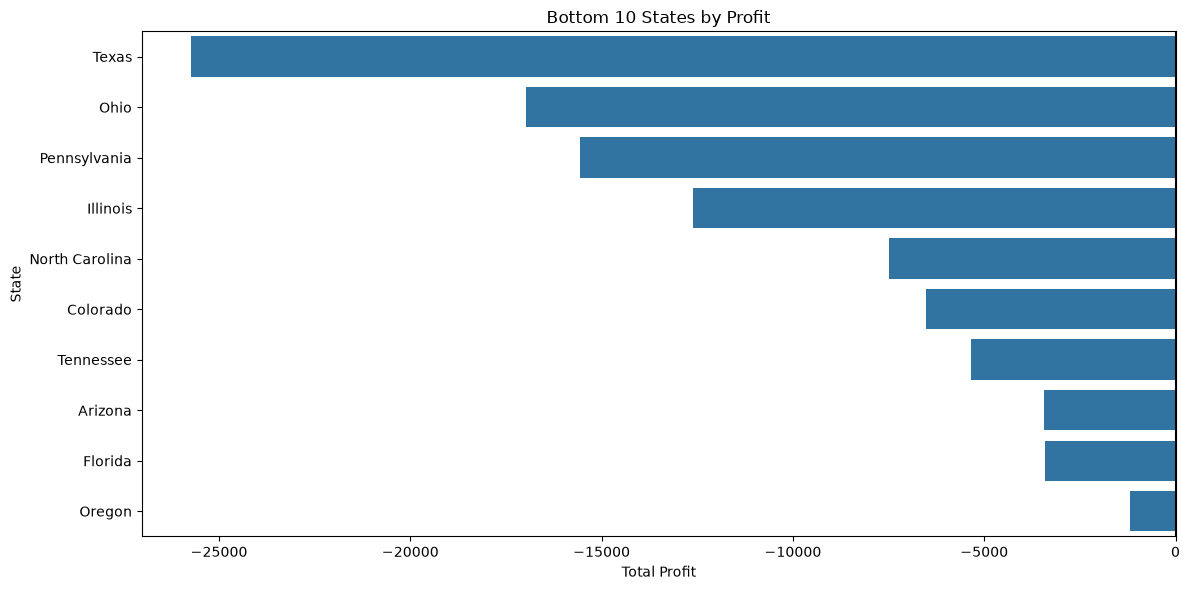

In [63]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=bottom_10_states.reset_index(),
    x="Total_Profit",
    y="State"
)

plt.axvline(x=0, color="black")
plt.title("Bottom 10 States by Profit")
plt.xlabel("Total Profit")
plt.ylabel("State")

plt.tight_layout()
plt.savefig("../outputs/charts/bottom_10_states_profit.png")
plt.show()

In [64]:
correlation_data = df_clean[
    ["Sales", "Quantity", "Discount", "Profit", "Shipping Days"]
]

correlation_matrix = correlation_data.corr()

correlation_matrix

,Sales,Quantity,Discount,Profit,Shipping Days
Sales,1.000000,0.200795,-0.028190,0.479064,-0.007354
Quantity,0.200795,1.000000,0.008623,0.066253,0.018298
Discount,-0.028190,0.008623,1.000000,-0.219487,0.000408
Profit,0.479064,0.066253,-0.219487,1.000000,-0.004649
Shipping Days,-0.007354,0.018298,0.000408,-0.004649,1.000000


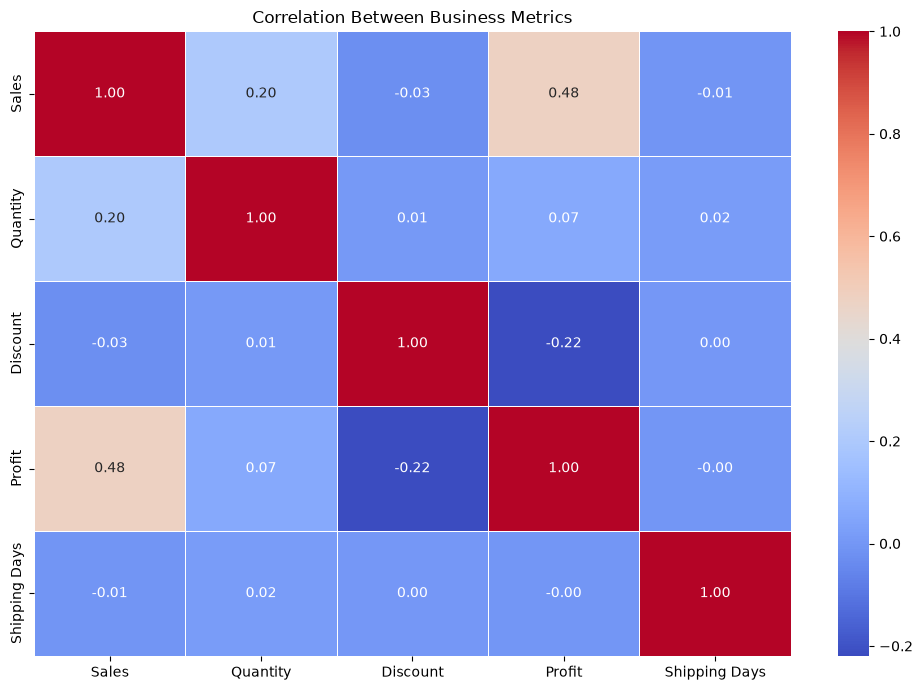

In [65]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Between Business Metrics")

plt.tight_layout()

plt.savefig("../outputs/charts/correlation_heatmap.png")
plt.show()

In [66]:
final_kpis = pd.DataFrame({
    "KPI": [
        "Total Sales",
        "Total Profit",
        "Total Orders",
        "Total Quantity Sold",
        "Average Order Value",
        "Profit Margin"
    ],
    "Value": [
        total_sales,
        total_profit,
        total_orders,
        total_quantity,
        average_order_value,
        profit_margin
    ]
})

final_kpis

,KPI,Value
0,Total Sales,2.297201e+06
1,Total Profit,2.863970e+05
2,Total Orders,5.009000e+03
3,Total Quantity Sold,3.787300e+04
4,Average Order Value,4.586147e+02
5,Profit Margin,1.246722e+01


In [67]:
best_category = category_analysis["Total_Profit"].idxmax()

worst_subcategory = subcategory_analysis["Total_Profit"].idxmin()

best_region = region_analysis["Total_Profit"].idxmax()

best_product = product_analysis["Total_Profit"].idxmax()

worst_product = product_analysis["Total_Profit"].idxmin()

best_customer = customer_analysis["Total_Profit"].idxmax()

print("BUSINESS INSIGHTS")
print("-------------------------")

print("Most Profitable Category:", best_category)
print("Most Loss-Making Sub-Category:", worst_subcategory)
print("Most Profitable Region:", best_region)
print("Most Profitable Product:", best_product)
print("Most Loss-Making Product:", worst_product)
print("Most Profitable Customer:", best_customer)

BUSINESS INSIGHTS
-------------------------
Most Profitable Category: Technology
Most Loss-Making Sub-Category: Tables
Most Profitable Region: West
Most Profitable Product: Canon imageCLASS 2200 Advanced Copier
Most Loss-Making Product: Cubify CubeX 3D Printer Double Head Print
Most Profitable Customer: ('TC-20980', 'Tamara Chand')


# E-Commerce Sales Analysis — Final Report

## 1. Project Overview
This project analyzes the Sample Superstore dataset to understand sales performance, profitability, customer behavior, product performance, and shipping operations.

## 2. Dataset Overview
- Total Records: 9,994
- Total Columns: 21
- Analysis Tool: Python
- Libraries: Pandas, NumPy, Matplotlib, Seaborn

## 3. Key Performance Indicators (KPIs)
- Total Sales: 2,297,200.86
- Total Profit: 286,397.02
- Total Orders: 5,009
- Total Quantity Sold: 37,873
- Average Order Value: 458.61
- Profit Margin: 12.47%

## 4. Key Business Findings
- Technology generated the highest category-level profit.
- West generated the highest regional sales and profit.
- Tables was the most loss-making sub-category, with a loss of 17,725.48.
- Some individual products generated substantial losses despite having significant sales.
- Discount levels and profitability require further investigation.

## 5. Business Recommendations
- Review pricing and discount strategies for loss-making products.
- Investigate the reasons behind losses in Tables and Bookcases.
- Focus on profitable products and categories.
- Study high-performing regions to identify growth opportunities.
- Improve customer retention using customer profitability analysis.

## 6. Conclusion
The analysis provides insights into business performance and identifies opportunities to improve profitability, optimize discounts, and make data-driven decisions.

In [68]:
category_report = df_clean.groupby("Category").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum")
).round(2)

display(category_report)

,Total_Sales,Total_Profit,Total_Quantity
Category,,,
Furniture,741999.80,18451.27,8028
Office Supplies,719047.03,122490.80,22906
Technology,836154.03,145454.95,6939


In [69]:
region_report = df_clean.groupby("Region").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order ID", "nunique")
).round(2)

display(region_report)

,Total_Sales,Total_Profit,Total_Orders
Region,,,
Central,501239.89,39706.36,1175
East,678781.24,91522.78,1401
South,391721.90,46749.43,822
West,725457.82,108418.45,1611


In [70]:
top_products_sales = df_clean.groupby("Product Name")["Sales"].sum().sort_values(ascending=False).head(10)
display(top_products_sales)

Product Name
Canon imageCLASS 2200 Advanced Copier                                          61599.824
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind    27453.384
Cisco TelePresence System EX90 Videoconferencing Unit                          22638.480
HON 5400 Series Task Chairs for Big and Tall                                   21870.576
GBC DocuBind TL300 Electric Binding System                                     19823.479
GBC Ibimaster 500 Manual ProClick Binding System                               19024.500
Hewlett Packard LaserJet 3310 Copier                                           18839.686
HP Designjet T520 Inkjet Large Format Printer - 24" Color                      18374.895
GBC DocuBind P400 Electric Binding System                                      17965.068
High Speed Automatic Electric Letter Opener                                    17030.312
Name: Sales, dtype: float64

In [71]:
top_products_profit = df_clean.groupby("Product Name")["Profit"].sum().sort_values(ascending=False).head(10)
display(top_products_profit)

Product Name
Canon imageCLASS 2200 Advanced Copier                                          25199.9280
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind     7753.0390
Hewlett Packard LaserJet 3310 Copier                                            6983.8836
Canon PC1060 Personal Laser Copier                                              4570.9347
HP Designjet T520 Inkjet Large Format Printer - 24" Color                       4094.9766
Ativa V4110MDD Micro-Cut Shredder                                               3772.9461
3D Systems Cube Printer, 2nd Generation, Magenta                                3717.9714
Plantronics Savi W720 Multi-Device Wireless Headset System                      3696.2820
Ibico EPK-21 Electric Binding System                                            3345.2823
Zebra ZM400 Thermal Label Printer                                               3343.5360
Name: Profit, dtype: float64

In [72]:
top_customers_sales = df_clean.groupby("Customer Name")["Sales"].sum().sort_values(ascending=False).head(10)
display(top_customers_sales)

Customer Name
Sean Miller           25043.050
Tamara Chand          19052.218
Raymond Buch          15117.339
Tom Ashbrook          14595.620
Adrian Barton         14473.571
Ken Lonsdale          14175.229
Sanjit Chand          14142.334
Hunter Lopez          12873.298
Sanjit Engle          12209.438
Christopher Conant    12129.072
Name: Sales, dtype: float64

In [73]:
top_customers_profit = df_clean.groupby("Customer Name")["Profit"].sum().sort_values(ascending=False).head(10)
display(top_customers_profit)

Customer Name
Tamara Chand            8981.3239
Raymond Buch            6976.0959
Sanjit Chand            5757.4119
Hunter Lopez            5622.4292
Adrian Barton           5444.8055
Tom Ashbrook            4703.7883
Christopher Martinez    3899.8904
Keith Dawkins           3038.6254
Andy Reiter             2884.6208
Daniel Raglin           2869.0760
Name: Profit, dtype: float64

In [74]:
loss_products = (
    df_clean.groupby("Product Name")["Profit"]
    .sum()
    .sort_values()
    .head(10)
)

display(loss_products)

Product Name
Cubify CubeX 3D Printer Double Head Print                           -8879.9704
Lexmark MX611dhe Monochrome Laser Printer                           -4589.9730
Cubify CubeX 3D Printer Triple Head Print                           -3839.9904
Chromcraft Bull-Nose Wood Oval Conference Tables & Bases            -2876.1156
Bush Advantage Collection Racetrack Conference Table                -1934.3976
GBC DocuBind P400 Electric Binding System                           -1878.1662
Cisco TelePresence System EX90 Videoconferencing Unit               -1811.0784
Martin Yale Chadless Opener Electric Letter Opener                  -1299.1836
Balt Solid Wood Round Tables                                        -1201.0581
BoxOffice By Design Rectangular and Half-Moon Meeting Room Tables   -1148.4375
Name: Profit, dtype: float64

In [75]:
discount_analysis = df_clean.groupby("Discount").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order ID", "nunique")
).round(2)

display(discount_analysis)

,Total_Sales,Total_Profit,Total_Orders
Discount,,,
0.00,1087908.47,320987.60,2644
0.10,54369.35,9029.18,89
0.15,27558.52,1418.99,51
0.20,764594.37,90337.31,2407
0.30,103226.66,-10369.28,211
0.32,14493.46,-2391.14,27
0.40,116417.78,-23057.05,185
0.45,5484.97,-2493.11,10
0.50,58918.54,-20506.43,64


In [76]:
shipping_report = df_clean.groupby("Ship Mode").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order ID", "nunique"),
    Average_Shipping_Days=("Shipping Days", "mean")
).round(2)

display(shipping_report)

,Total_Sales,Total_Profit,Total_Orders,Average_Shipping_Days
Ship Mode,,,,
First Class,351428.42,48969.84,787,2.18
Same Day,128363.12,15891.76,264,0.04
Second Class,459193.57,57446.64,964,3.24
Standard Class,1358215.74,164088.79,2994,5.01


In [77]:
top_states_sales = (
    df_clean.groupby("State")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

display(top_states_sales)

State
California      457687.6315
New York        310876.2710
Texas           170188.0458
Washington      138641.2700
Pennsylvania    116511.9140
Florida          89473.7080
Illinois         80166.1010
Ohio             78258.1360
Michigan         76269.6140
Virginia         70636.7200
Name: Sales, dtype: float64

In [78]:
bottom_states_profit = (
    df_clean.groupby("State")["Profit"]
    .sum()
    .sort_values()
    .head(10)
)

display(bottom_states_profit)

State
Texas            -25729.3563
Ohio             -16971.3766
Pennsylvania     -15559.9603
Illinois         -12607.8870
North Carolina    -7490.9122
Colorado          -6527.8579
Tennessee         -5341.6936
Arizona           -3427.9246
Florida           -3399.3017
Oregon            -1190.4705
Name: Profit, dtype: float64